# S8 · Schaefer100 SVD/gradient


In [2]:
from pathlib import Path
import sys

base_path = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "CODE").is_dir() and (p / "DATA").is_dir()
)

sys.path.insert(0, str(Path(base_path) / 'CODE'))


In [3]:
import os 
import numpy as np
import pandas as pd

svd_root = f"{base_path}/RESULTS/replication_dataset/svd"
output_path = f"{base_path}/FIGURES/supplementary/Fig_S8"
os.makedirs(output_path, exist_ok=True)

config_dirs = {
    # "rest": f"{svd_root}/rest",
    # "task": f"{svd_root}/task",
    "all":  f"{svd_root}/all"
}

In [4]:
from utils.svd import load_svd_result_legacy as load_svd_result

In [5]:
results = {}

# load svd
for config_name, config_dir in config_dirs.items():
    results[config_name] = load_svd_result(config_dir, orient_components=False)

first_component = results['all']['U'][:, 0]

# load gradient
gradient = pd.read_csv(f"{base_path}/DATA/gradients/Margulies_gradient1_Schaefer100_7Networks.csv")
first_gradient = gradient["MarguliesGradient1"].values

In [6]:
from scipy.stats import pearsonr, spearmanr

corr, p_value = pearsonr(first_component, first_gradient)
print(f"Pearson correlation: {corr:.4f}, p-value: {p_value:.4f}")

corr, p_value = spearmanr(first_component, first_gradient)
print(f"Spearman correlation: {corr:.4f}, p-value: {p_value:.4f}")

Pearson correlation: -0.2797, p-value: 0.0048
Spearman correlation: -0.2043, p-value: 0.0415


In [7]:
# SPIN TEST: SVD component 1 vs Margulies Gradient 1
# Schaefer100, 7 networks

import numpy as np

from netneurotools.datasets import fetch_schaefer2018
from neuromaps.images import annot_to_gifti
from neuromaps import nulls
from neuromaps.stats import compare_images


# 1. Data
component = np.asarray(first_component).squeeze()
gradient1 = np.asarray(first_gradient).squeeze()

assert component.shape == gradient1.shape
assert len(component) == 100

print("Number of parcels:", len(component))


# 2. Get Schaefer100 parcellation in fsaverage5
#    fsaverage5 = ~10k vertices / hemisphere
schaefer = fetch_schaefer2018(
    version="fsaverage5",
    verbose=0
)

schaefer100 = schaefer["100Parcels7Networks"]

# Convert FreeSurfer .annot files to GIFTI,
# which neuromaps can use
parcellation = annot_to_gifti(
    (
        str(schaefer100.L),
        str(schaefer100.R)
    )
)


# 3. Generate spatial null maps
N_PERM = 10000
SEED = 42

rotated_component = nulls.vasa(
    component,
    atlas="fsaverage",
    density="10k",
    parcellation=parcellation,
    n_perm=N_PERM,
    seed=SEED
)

print("Null maps shape:", rotated_component.shape)
# expected: (100, 10000)


# 4. Pearson correlation + spin p-value
r_pearson, p_spin_pearson = compare_images(
    component,
    gradient1,
    metric="pearsonr",
    nulls=rotated_component,
    ignore_zero=False
)

print(
    f"Pearson: r = {r_pearson:.4f}, "
    f"p_spin = {p_spin_pearson:.5f}"
)


# 5. Spearman correlation + spin p-value
rho_spearman, p_spin_spearman = compare_images(
    component,
    gradient1,
    metric="spearmanr",
    nulls=rotated_component,
    ignore_zero=False
)

print(
    f"Spearman: rho = {rho_spearman:.4f}, "
    f"p_spin = {p_spin_spearman:.5f}"
)

Number of parcels: 100
Null maps shape: (100, 10000)
Pearson: r = -0.2797, p_spin = 0.03440
Spearman: rho = -0.2043, p_spin = 0.12529


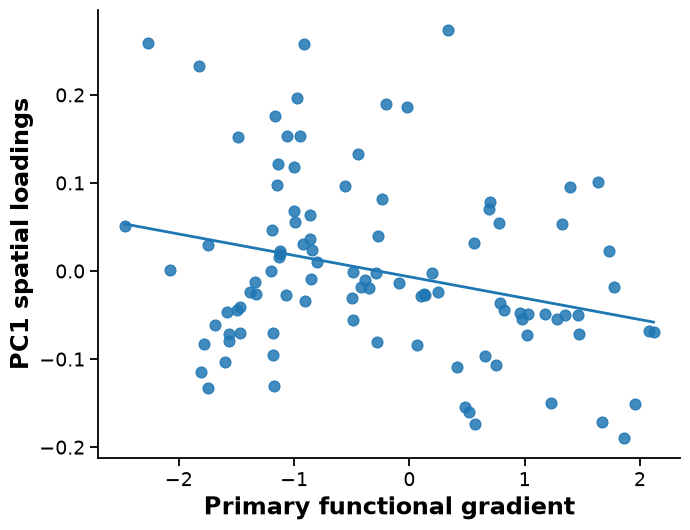

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# input
component = np.asarray(first_component).squeeze()
gradient = np.asarray(first_gradient).squeeze()

# Correlation type: "pearson" or "spearman"
corr_type = "pearson"


# 2. Figure
fig, ax = plt.subplots(figsize=(7, 5.4))

# Scatter
ax.scatter(
    gradient,
    component,
    s=60,
    alpha=0.85
)

# Regression line (for visualization)
m, b = np.polyfit(gradient, component, 1)
xline = np.linspace(np.min(gradient), np.max(gradient), 200)
ax.plot(xline, m * xline + b, linewidth=2.0)

# Labels
ax.set_xlabel("Primary functional gradient", fontsize=17, fontweight="bold")
ax.set_ylabel("PC1 spatial loadings", fontsize=17, fontweight="bold")

# Ticks: large, but NOT bold
ax.tick_params(axis="both", labelsize=14, width=1.3, length=6)

# Clean spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.3)
ax.spines["bottom"].set_linewidth(1.3)

plt.tight_layout()
plt.show()


# 3. Save
fig.savefig(f"{output_path}/PC1_vs_gradient_scatter.png", dpi=300, bbox_inches="tight")